In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned modeling dataset
data_path = Path("../data/processed/rossmann_modeling.csv")

df = pd.read_csv(data_path, parse_dates=["Date"])

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())

/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_51762/1898113397.py:8: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path, parse_dates=["Date"])


Dataset shape: (844338, 23)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistanceMissing,Year,Month,Day,WeekOfYear
0,85,2,2013-01-01,4220,619,1,0,a,1,b,...,2011.0,0,NaN,NaN,NaN,0,2013,1,1,1
1,259,2,2013-01-01,6851,1444,1,0,a,1,b,...,NaN,0,NaN,NaN,NaN,0,2013,1,1,1
2,262,2,2013-01-01,17267,2875,1,0,a,1,b,...,2013.0,0,NaN,NaN,NaN,0,2013,1,1,1
3,274,2,2013-01-01,3102,729,1,0,a,1,b,...,NaN,1,10.0,2013.0,"Jan,Apr,Jul,Oct",0,2013,1,1,1
4,335,2,2013-01-01,2401,482,1,0,a,1,b,...,NaN,1,31.0,2013.0,"Jan,Apr,Jul,Oct",0,2013,1,1,1


Average sales by weekday:
DayOfWeek
1    8216.25
2    7088.41
3    6728.79
4    6768.21
5    7073.03
6    5875.08
7    8224.72
Name: Sales, dtype: float64


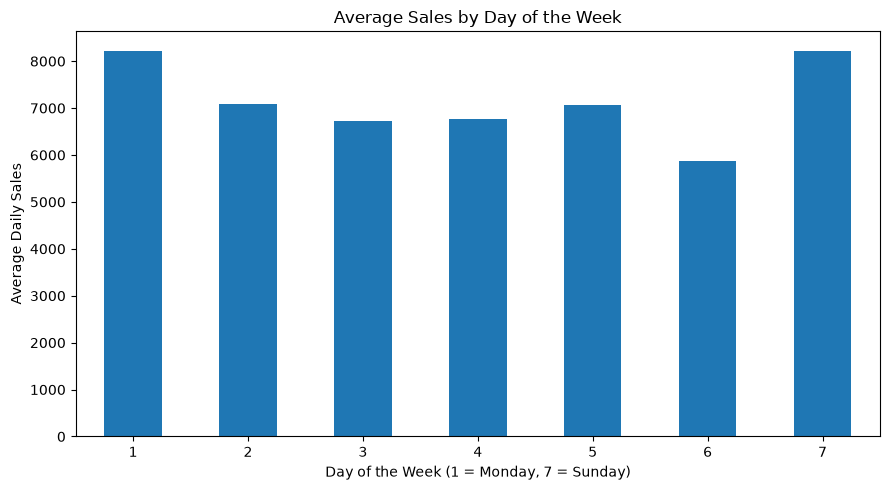

In [10]:
# Calculate average sales for each weekday
weekday_sales = df.groupby("DayOfWeek")["Sales"].mean()

print("Average sales by weekday:")
print(weekday_sales.round(2))

# Visualize the results
plt.figure(figsize=(9, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day of the Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Average sales by promotion status:
Promo
0    5929.83
1    8228.74
Name: Sales, dtype: float64


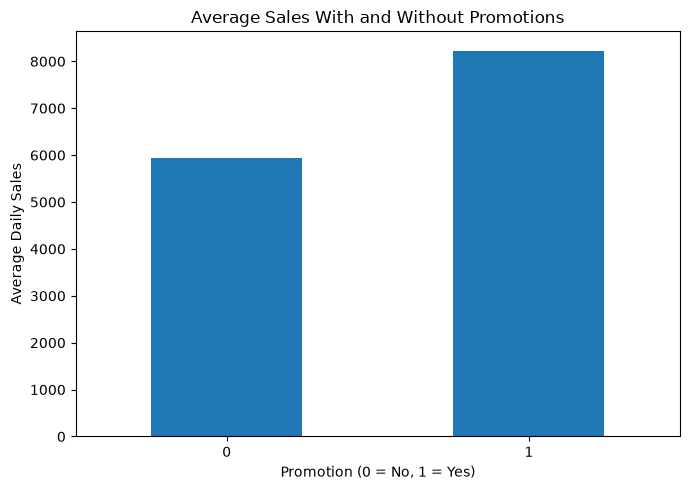

In [11]:
# Calculate average sales with and without promotions
promo_sales = df.groupby("Promo")["Sales"].mean()

print("Average sales by promotion status:")
print(promo_sales.round(2))

# Visualize the results
plt.figure(figsize=(7, 5))

promo_sales.plot(kind="bar")

plt.title("Average Sales With and Without Promotions")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Average sales by store type:
StoreType
a     6925.70
b    10233.38
c     6933.13
d     6822.30
Name: Sales, dtype: float64


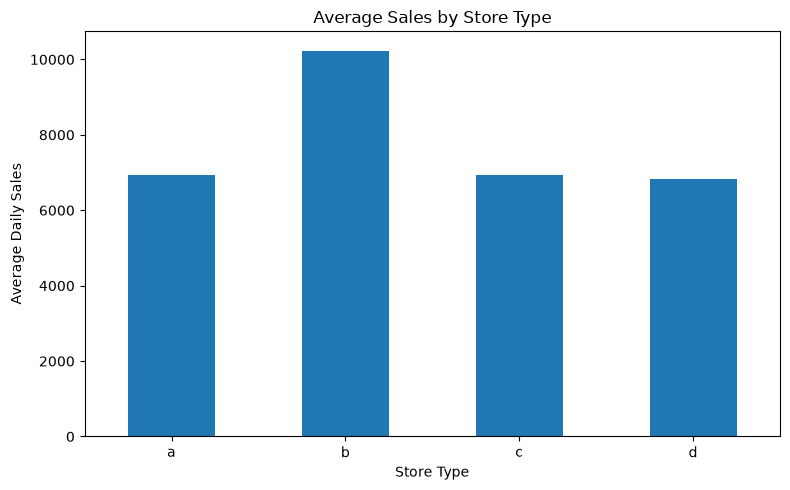

In [12]:
# Calculate average sales by store type
store_type_sales = df.groupby("StoreType")["Sales"].mean()

print("Average sales by store type:")
print(store_type_sales.round(2))

# Visualize the results
plt.figure(figsize=(8, 5))

store_type_sales.plot(kind="bar")

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Average sales by month:
Month
1     6564.30
2     6589.49
3     6976.82
4     7046.66
5     7106.81
6     7001.40
7     6953.58
8     6649.23
9     6547.47
10    6602.97
11    7188.55
12    8608.96
Name: Sales, dtype: float64


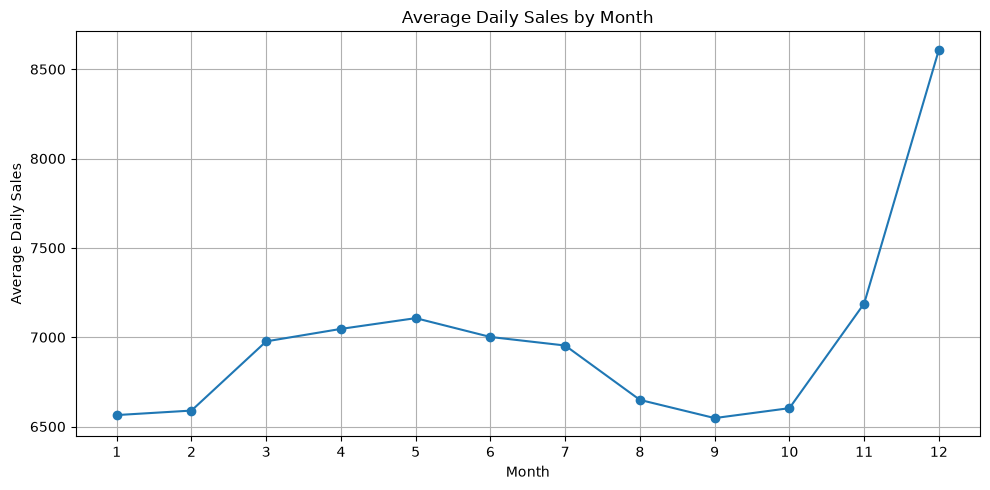

In [13]:
# Calculate average daily sales by month
monthly_sales = df.groupby("Month")["Sales"].mean()

print("Average sales by month:")
print(monthly_sales.round(2))

# Visualize the results
plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()


Monthly sales trend:
Date
2013-01-01    6240.51
2013-02-01    6428.84
2013-03-01    7213.09
2013-04-01    6579.79
2013-05-01    7077.03
2013-06-01    6467.75
2013-07-01    6923.61
2013-08-01    6596.37
2013-09-01    6363.62
2013-10-01    6473.35
2013-11-01    6904.51
2013-12-01    8613.46
2014-01-01    6540.31
2014-02-01    6678.54
2014-03-01    6654.71
2014-04-01    7227.59
2014-05-01    6948.12
2014-06-01    7251.21
2014-07-01    6893.94
2014-08-01    6714.31
2014-09-01    6758.81
2014-10-01    6757.60
2014-11-01    7539.60
2014-12-01    8603.81
2015-01-01    6913.18
2015-02-01    6660.52
2015-03-01    7071.48
2015-04-01    7349.11
2015-05-01    7308.78
2015-06-01    7295.62
2015-07-01    7033.34
Freq: MS, Name: Sales, dtype: float64


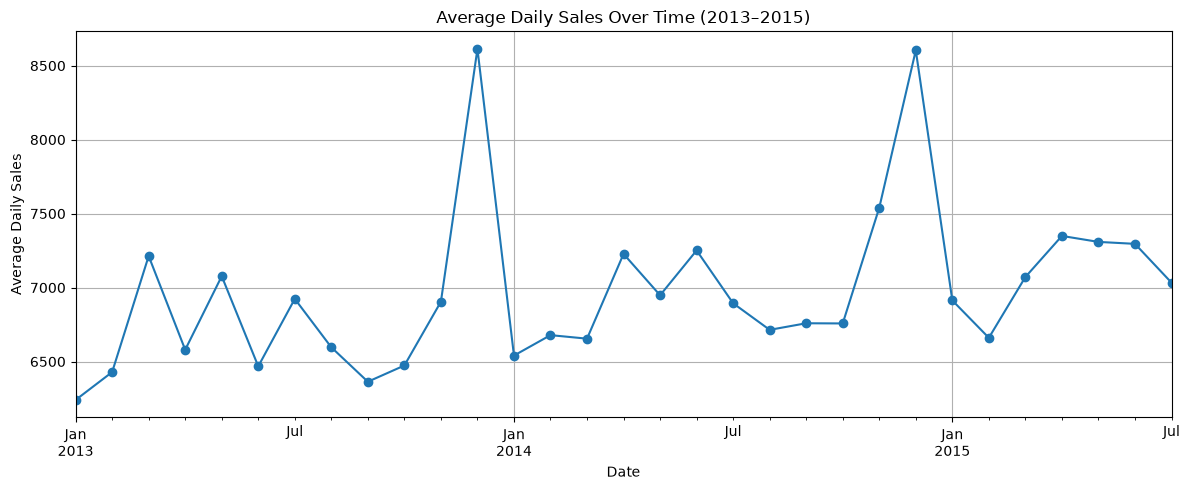

In [14]:
# Calculate average daily sales for each calendar month
sales_trend = (
    df.groupby(pd.Grouper(key="Date", freq="MS"))["Sales"]
    .mean()
)

print("Monthly sales trend:")
print(sales_trend.round(2))

# Visualize the trend
plt.figure(figsize=(12, 5))

sales_trend.plot(kind="line", marker="o")

plt.title("Average Daily Sales Over Time (2013–2015)")
plt.xlabel("Date")
plt.ylabel("Average Daily Sales")
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:
# Split the dataset chronologically
train_data = df[df["Date"] < "2015-06-01"].copy()
test_data = df[df["Date"] >= "2015-06-01"].copy()

# Calculate average sales for each weekday using training data
weekday_averages = train_data.groupby("DayOfWeek")["Sales"].mean()

# Predict sales for the test data
test_data["PredictedSales"] = test_data["DayOfWeek"].map(
    weekday_averages
)

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

display(
    test_data[["Date", "Store", "DayOfWeek", "Sales", "PredictedSales"]].head(10)
)


Training records: 785727
Testing records: 58611


,Date,Store,DayOfWeek,Sales,PredictedSales
785727,2015-06-01,1,1,5774,8191.145314
785728,2015-06-01,2,1,6629,8191.145314
785729,2015-06-01,3,1,11594,8191.145314
785730,2015-06-01,4,1,13727,8191.145314
785731,2015-06-01,5,1,8396,8191.145314
785732,2015-06-01,6,1,7054,8191.145314
785733,2015-06-01,7,1,14160,8191.145314
785734,2015-06-01,8,1,10971,8191.145314
785735,2015-06-01,9,1,12227,8191.145314
785736,2015-06-01,10,1,7846,8191.145314


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual sales
actual = test_data["Sales"]

# Predicted sales
predicted = test_data["PredictedSales"]

# Calculate errors
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Baseline Model Evaluation")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

Baseline Model Evaluation
MAE: 2199.64
RMSE: 3009.76
